# Sourcing case: EAF in France

A 2 Mt/yr EAF on the coast in France, based on the public plan for ArcelorMittal Dunkirk (start 2029, 60% scrap, 20% DRI, 20% hot metal). Costs are estimates from public sources.

Sources:
- scrap and HBI prices Sep 2026: https://www.spglobal.com/energy/en/news-research/latest-news/metals/093026-europes-scrap-demand-set-to-surge-as-new-eafs-loom-eurofer
- CBAM certificate price Q1 2026: https://www.spglobal.com/energy/en/news-research/latest-news/energy-transition/040726-brussels-confirms-first-cbam-certificate-price-for-q1-2026-at-eur7536mtco2e
- pig iron price: notebook 1

In [1]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

from scipy.optimize import linprog

c:\Users\Athul\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\interactiveshell.py:3141: SyntaxWarning: 'return' in a 'finally' block
  return result


ModuleNotFoundError: No module named 'seaborn'

## How much scrap does it need?

In [2]:
capacity = 2.0
utilisation = 0.80
steel = capacity * utilisation
scrap_need = steel * 1.10 * 0.60

ms = pd.read_csv('../data/processed/member_state_net_2025.csv').set_index('member_state')
france_surplus = ms.loc['FR', 'net_total_mt']
fos_need = 2.1 * utilisation * 1.10 * 0.85

print(f'Liquid steel: {steel:.2f} Mt/yr, scrap needed: {scrap_need:.2f} Mt/yr')
print(f"France's net scrap surplus 2025: {france_surplus:.2f} Mt")
print(f'Dunkirk alone uses {scrap_need / france_surplus:.0%} of it')
print(f'With the planned Fos-sur-Mer EAF: {(scrap_need + fos_need) / france_surplus:.0%}')

Liquid steel: 1.60 Mt/yr, scrap needed: 1.06 Mt/yr
France's net scrap surplus 2025: 4.36 Mt
Dunkirk alone uses 24% of it
With the planned Fos-sur-Mer EAF: 60%


## Prices and CO2
- scrap 325 EUR/t + 15 delivery, HBI 396.5 USD/t + 10 (USD/EUR from the same article), pig iron = 2026 import price, own hot metal 330 EUR/t (my guess)
- CO2: pig iron 1.21 t/t and DRI 0.40 t/t (CBAM default values), hot metal 1.9 t/t
- share of CO2 actually paid: 5% in 2027, 48.5% in 2030 (CBAM phase-in)

In [3]:
trade = pd.read_csv('../data/processed/fact_trade_monthly.csv', dtype={'product': str})
pi = trade[(trade['partner'] == 'EXT_EU') & (trade['product'] == '7201') & (trade['flow'] == 'import') & (trade['year'] == 2026)]
pig_iron_price = pi['eur'].sum() / pi['tonnes'].sum()

inputs = DataFrame({
    'price_eur_t': [325 + 15, 396.50 / (369 / 325) + 10, pig_iron_price, 330],
    'yield': [0.90, 0.87, 0.93, 0.93],
    'co2_t_per_t': [0, 0.40, 1.21, 1.90]},
    index=['Scrap', 'DRI/HBI', 'Pig iron', 'Hot metal (own BF)'])
paid_share = {2027: 0.05, 2030: 0.485}
inputs

,price_eur_t,yield,co2_t_per_t
Scrap,340.000000,0.90,0.00
DRI/HBI,359.220867,0.87,0.40
Pig iron,406.303883,0.93,1.21
Hot metal (own BF),330.000000,0.93,1.90


In [4]:
def input_cost(year, co2_price=75, scrap_up=0.0):
    c = inputs.copy()
    c.loc['Scrap', 'price_eur_t'] = c.loc['Scrap', 'price_eur_t'] * (1 + scrap_up)
    c['carbon_eur_t'] = c['co2_t_per_t'] * co2_price * paid_share[year]
    c['cost_per_t_steel'] = (c['price_eur_t'] + c['carbon_eur_t']) / c['yield']
    return c

costs = pd.concat([input_cost(2027).assign(year=2027), input_cost(2030).assign(year=2030)])
costs = costs.reset_index().rename(columns={'index': 'input'})
costs[['year', 'input', 'price_eur_t', 'carbon_eur_t', 'cost_per_t_steel']]

,year,input,price_eur_t,carbon_eur_t,cost_per_t_steel
0,2027,Scrap,340.000000,0.00000,377.777778
1,2027,DRI/HBI,359.220867,1.50000,414.621686
2,2027,Pig iron,406.303883,4.53750,441.764928
3,2027,Hot metal (own BF),330.000000,7.12500,362.500000
4,2030,Scrap,340.000000,0.00000,377.777778
5,2030,DRI/HBI,359.220867,14.55000,429.621686
6,2030,Pig iron,406.303883,44.01375,484.212509
7,2030,Hot metal (own BF),330.000000,69.11250,429.153226


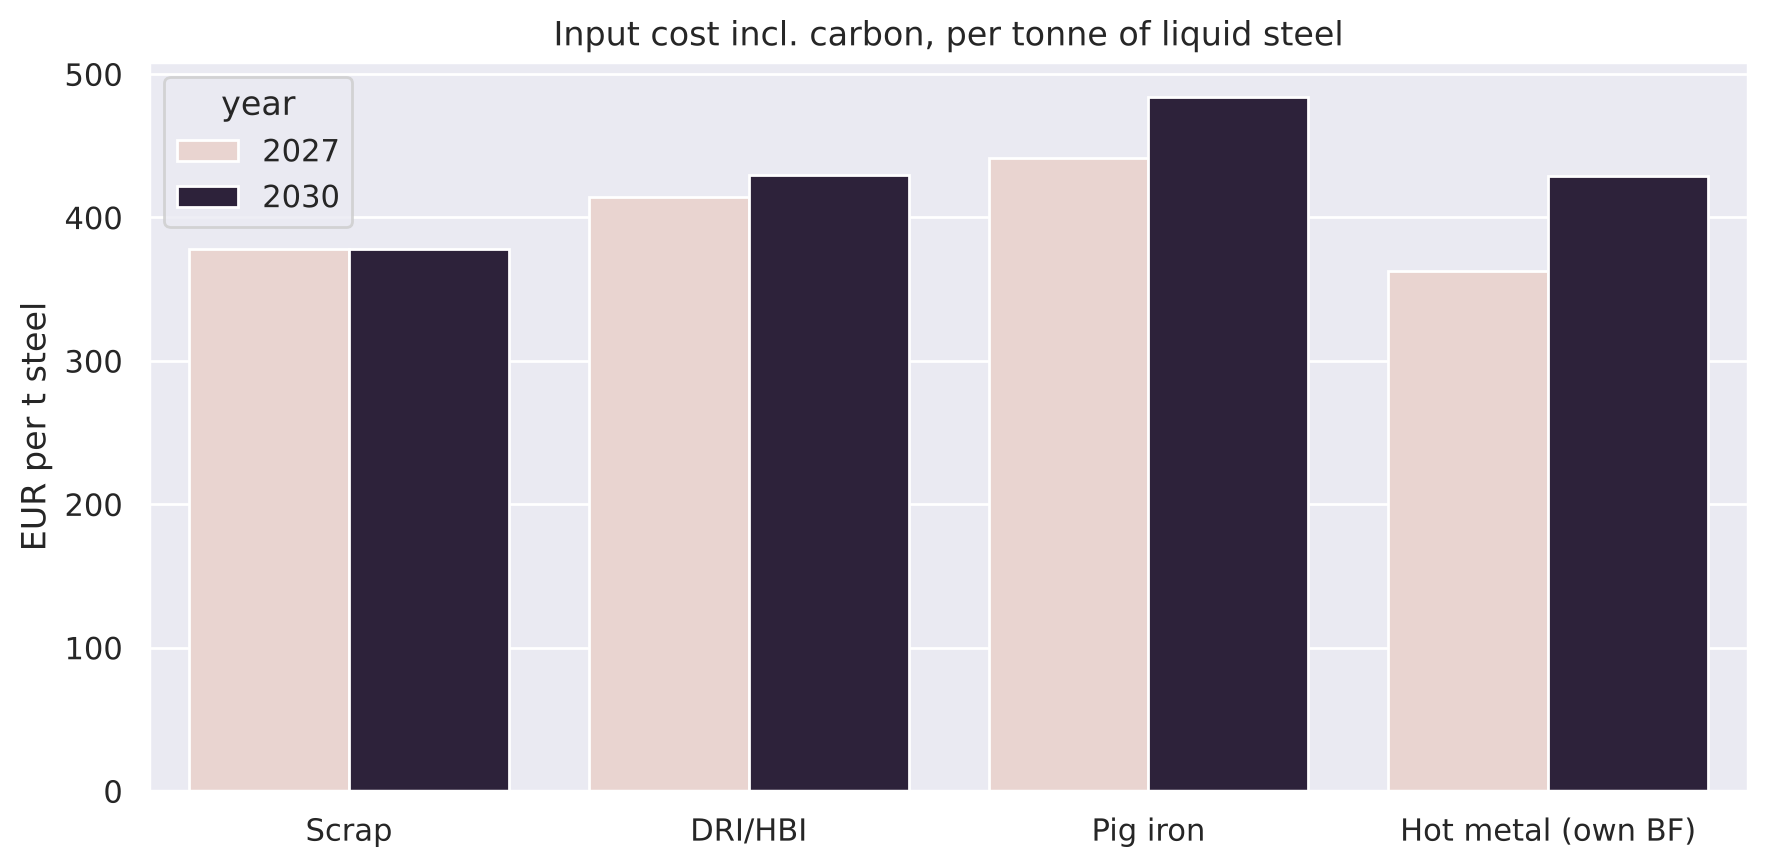

In [5]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=costs, x='input', y='cost_per_t_steel', hue='year')
plt.title('Input cost incl. carbon, per tonne of liquid steel')
plt.ylabel('EUR per t steel')
plt.xlabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/11_input_cost_carbon.png')
plt.show()

## Cheapest mix (linprog)
constraints: primary metallics at least 30%, hot metal max 20%, pig iron max 15%, DRI max 40%

In [6]:
def best_mix(year, co2_price=75, scrap_up=0.0):
    c = input_cost(year, co2_price, scrap_up)
    cost = (c['price_eur_t'] + c['carbon_eur_t']).values
    A_ub = [[0.30, -0.70, -0.70, -0.70],
            [-0.20, -0.20, -0.20, 0.80],
            [-0.15, -0.15, 0.85, -0.15],
            [-0.40, 0.60, -0.40, -0.40]]
    b_ub = [0, 0, 0, 0]
    r = linprog(cost, A_ub=A_ub, b_ub=b_ub, A_eq=[c['yield'].values], b_eq=[1], bounds=[(0, None)] * 4, method='highs')
    share = r.x / r.x.sum()
    return list(share) + [r.fun]

rows = []
for year in [2027, 2030]:
    for up in [0, 0.15, 0.30]:
        for co2 in [75, 120]:
            rows.append([year, up, co2] + best_mix(year, co2, up))

mix = DataFrame(rows, columns=['year', 'scrap_price_uplift', 'co2_price', 'share_Scrap', 'share_DRI/HBI',
                               'share_Pig iron', 'share_Hot metal (own BF)', 'cost_eur_per_t_steel'])
mix.round(2)

,year,scrap_price_uplift,co2_price,share_Scrap,share_DRI/HBI,share_Pig iron,share_Hot metal (own BF),cost_eur_per_t_steel
0,2027,0.00,75,0.70,0.1,0.00,0.2,378.18
1,2027,0.00,120,0.70,0.1,0.00,0.2,379.23
2,2027,0.15,75,0.40,0.4,0.00,0.2,411.76
3,2027,0.15,120,0.40,0.4,0.00,0.2,413.12
4,2027,0.30,75,0.25,0.4,0.15,0.2,427.20
5,2027,0.30,120,0.25,0.4,0.15,0.2,429.01
6,2030,0.00,75,0.70,0.3,0.00,0.0,392.96
7,2030,0.00,120,0.70,0.3,0.00,0.0,395.90
8,2030,0.15,75,0.40,0.4,0.00,0.2,431.47
9,2030,0.15,120,0.70,0.3,0.00,0.0,435.97


In [7]:
plan = np.array([0.6, 0.2, 0, 0.2])
for year in [2027, 2030]:
    c = input_cost(year)
    plan_cost = (plan * (c['price_eur_t'] + c['carbon_eur_t'])).sum() / (plan * c['yield']).sum()
    print(f'{year}: announced mix {plan_cost:.0f} EUR/t steel, cheapest mix {best_mix(year)[-1]:.0f} EUR/t steel')

extra = (mix.loc[(mix['year'] == 2027) & (mix['co2_price'] == 75), 'cost_eur_per_t_steel'].values - best_mix(2027)[-1]) * steel
print('Extra cost per year if scrap +15% / +30%: {:.0f} / {:.0f} million EUR'.format(extra[1], extra[2]))

2027: announced mix 382 EUR/t steel, cheapest mix 378 EUR/t steel
2030: announced mix 398 EUR/t steel, cheapest mix 393 EUR/t steel
Extra cost per year if scrap +15% / +30%: 54 / 78 million EUR


## Break-even scrap price, 2030

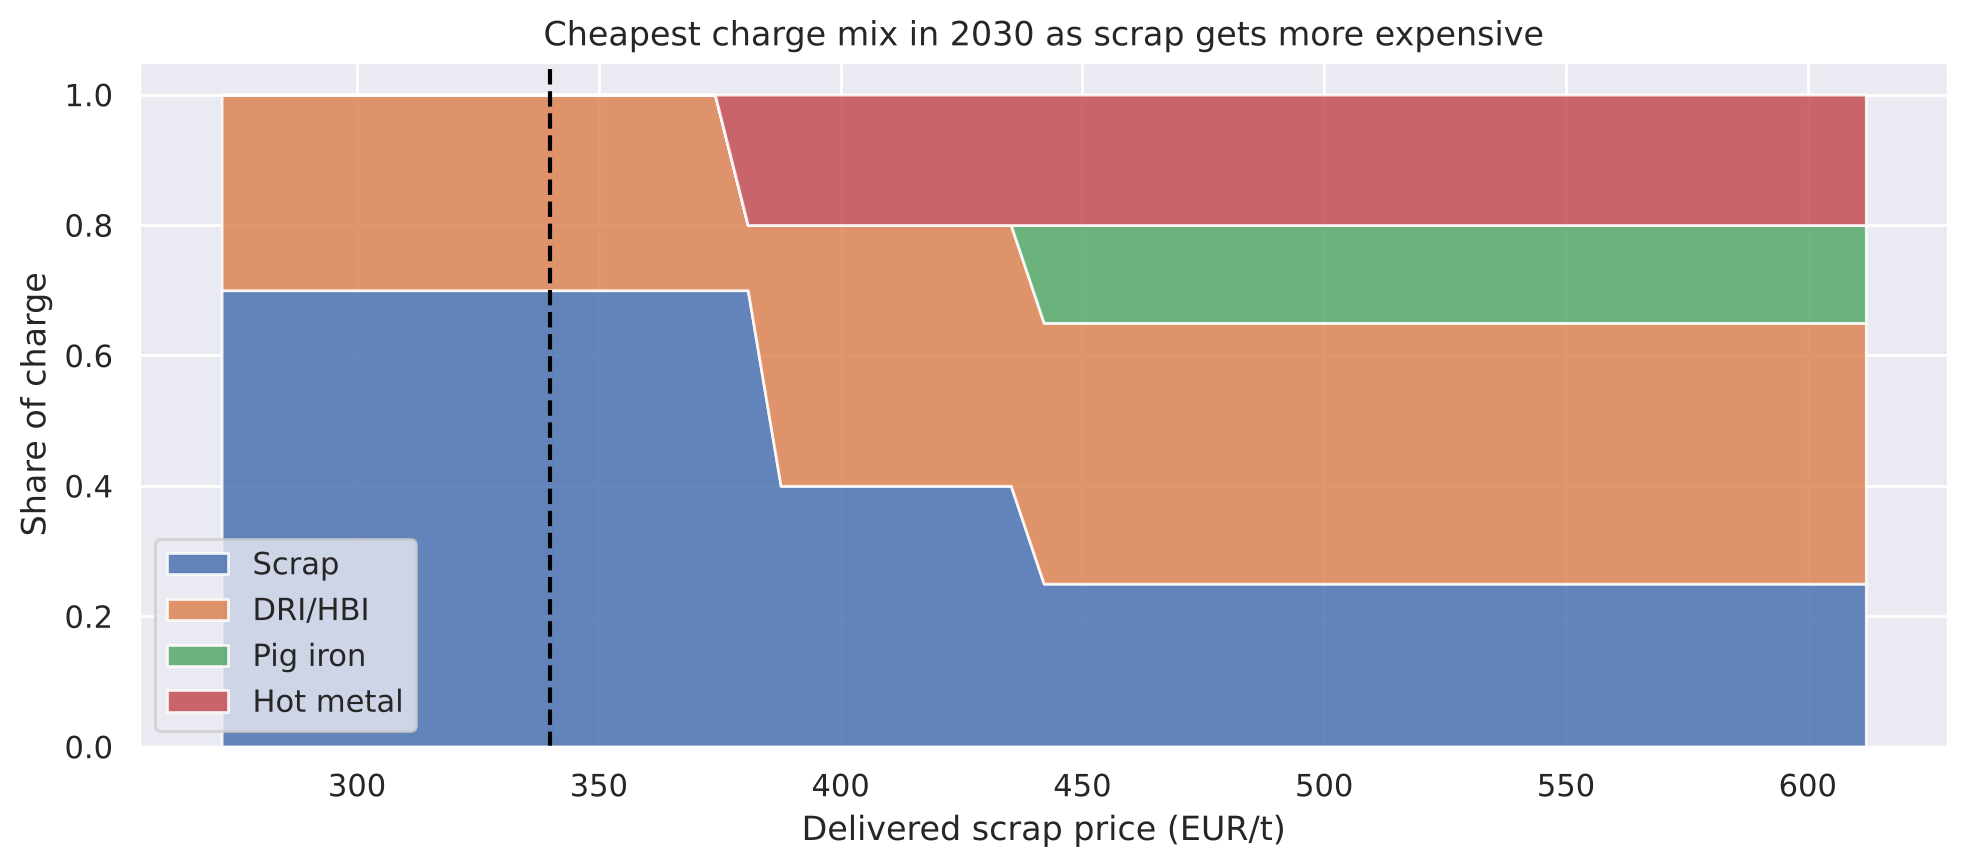

Scrap stays at max share up to about 388 EUR/t (today 340)


In [8]:
ups = np.linspace(-0.2, 0.8, 51)
be = DataFrame([best_mix(2030, 75, u) for u in ups], columns=['Scrap', 'DRI/HBI', 'Pig iron', 'Hot metal', 'cost'])
be['scrap_price'] = inputs.loc['Scrap', 'price_eur_t'] * (1 + ups)

plt.figure(figsize=(10, 4.5))
plt.stackplot(be['scrap_price'], be['Scrap'], be['DRI/HBI'], be['Pig iron'], be['Hot metal'],
              labels=['Scrap', 'DRI/HBI', 'Pig iron', 'Hot metal'], alpha=0.85)
plt.axvline(inputs.loc['Scrap', 'price_eur_t'], color='black', linestyle='--')
plt.xlabel('Delivered scrap price (EUR/t)')
plt.ylabel('Share of charge')
plt.title('Cheapest charge mix in 2030 as scrap gets more expensive')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig('../outputs/figures/12_breakeven_mix.png')
plt.show()

switch = be[be['Scrap'] < be['Scrap'].max() - 1e-6]['scrap_price'].min()
print('Scrap stays at max share up to about {:.0f} EUR/t (today {:.0f})'.format(switch, inputs.loc['Scrap', 'price_eur_t']))

## Sourcing options
scores 1-5 are my own judgement, weights put security of supply first

In [9]:
weights = Series({'cost': 0.30, 'security': 0.30, 'carbon': 0.15, 'quality': 0.15, 'flexibility': 0.10})

options = DataFrame({
    'Spot purchases only':                      [4, 1, 5, 2, 5],
    'Long-term contracts with recyclers':       [3, 4, 5, 4, 3],
    'Own scrap collection (buy/partner)':       [3, 5, 5, 4, 2],
    'DRI/HBI offtake, non-Russian origin':      [3, 3, 3, 5, 2],
    'Pig iron imports':                         [2, 2, 1, 5, 4]}, index=weights.index).T

options['weighted_score'] = (options[weights.index] * weights).sum(axis=1)
options.sort_values('weighted_score', ascending=False)

,cost,security,carbon,quality,flexibility,weighted_score
Own scrap collection (buy/partner),3,5,5,4,2,3.95
Long-term contracts with recyclers,3,4,5,4,3,3.75
"DRI/HBI offtake, non-Russian origin",3,3,3,5,2,3.20
Spot purchases only,4,1,5,2,5,3.05
Pig iron imports,2,2,1,5,4,2.50


In [10]:
costs[['year', 'input', 'price_eur_t', 'carbon_eur_t', 'cost_per_t_steel']].to_csv('../data/processed/input_costs_carbon.csv', index=False)
mix.to_csv('../data/processed/charge_mix_scenarios.csv', index=False)
options.reset_index().rename(columns={'index': 'option'}).to_csv('../data/processed/sourcing_options_scored.csv', index=False)